# Atividade Prática 03
- Final da Disciplina: Análise de Rede Neural MLP
## Curso
- Pós-IA-ML / Introdução a Ciência de Dados
## Aluno
- Charles Balmant Villalba

# **Selecione a métrica de avaliação que você ache relevante para o problema, justificando a resposta. Além disso, apresente a matriz de confusão para todas as execuções considerando o melhor modelo;**

Conforme solicitado temos como base de trabalho dados sobre câncer de mama. Trata-se, portanto, de um assunto muito delicado e que pode causar grande impacto na qualidade de vida do paciente diagnosticado. Para além da ansiedade, tem-se que o falso negativo poderá acarretar em fatalidade. Desta forma, a métrica de mais importa avaliação - na opinião deste aluno, é a métrica Recall.

Recall mede a proporção de tumores malignos que foram identificados corretamente pelo modelo. Assim, quanto maior seu valor, menor a proporção de casos malignos sem detecção.

In [24]:
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import KFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline

cancer_data = load_breast_cancer()

X = pd.DataFrame(cancer_data.data, columns=cancer_data.feature_names)
y = cancer_data.target

print(f"Dimensões da base: {X.shape[0]} pacientes e {X.shape[1]} características.")
print("-" * 50)

modelo_pipeline = make_pipeline(
    StandardScaler(),
    MLPClassifier(hidden_layer_sizes=(30, 15), max_iter=1000, random_state=42)
)

kf = KFold(n_splits=5, shuffle=True, random_state=42)

print("\n--- TAMANHO DAS DIVISÕES (TREINO / TESTE) ---")

for fold, (indices_treino, indices_teste) in enumerate(kf.split(X)):
    qtd_treino = len(indices_treino)
    qtd_teste = len(indices_teste)
    print(f"Fold {fold + 1}: Treino com {qtd_treino} instâncias | Teste com {qtd_teste} instâncias")

print("-" * 50)

metricas = ['accuracy', 'precision', 'recall']

print("\nExecutando o treinamento e validação em 5 Folds...")
resultados = cross_validate(modelo_pipeline, X, y, cv=kf, scoring=metricas)

for i in range(5):
    print(f"Fold {i+1} | "
          f"Acurácia: {resultados['test_accuracy'][i]*100:.2f}% | "
          f"Precisão: {resultados['test_precision'][i]*100:.2f}% | "
          f"Recall: {resultados['test_recall'][i]*100:.2f}%")

print("-" * 50)
print("\n--- DESEMPENHO MÉDIO FINAL ---")

print(f"Acurácia Média: {resultados['test_accuracy'].mean() * 100:.2f}% "
      f"(± {resultados['test_accuracy'].std() * 100:.2f}%)")

print(f"Precisão Média: {resultados['test_precision'].mean() * 100:.2f}% "
      f"(± {resultados['test_precision'].std() * 100:.2f}%)")

print(f"Recall Médio:   {resultados['test_recall'].mean() * 100:.2f}% "
      f"(± {resultados['test_recall'].std() * 100:.2f}%)")
print("-" * 30)

Dimensões da base: 569 pacientes e 30 características.
--------------------------------------------------

--- TAMANHO DAS DIVISÕES (TREINO / TESTE) ---
Fold 1: Treino com 455 instâncias | Teste com 114 instâncias
Fold 2: Treino com 455 instâncias | Teste com 114 instâncias
Fold 3: Treino com 455 instâncias | Teste com 114 instâncias
Fold 4: Treino com 455 instâncias | Teste com 114 instâncias
Fold 5: Treino com 456 instâncias | Teste com 113 instâncias
--------------------------------------------------

Executando o treinamento e validação em 5 Folds...
Fold 1 | Acurácia: 98.25% | Precisão: 98.59% | Recall: 98.59%
Fold 2 | Acurácia: 99.12% | Precisão: 100.00% | Recall: 98.70%
Fold 3 | Acurácia: 96.49% | Precisão: 95.89% | Recall: 98.59%
Fold 4 | Acurácia: 97.37% | Precisão: 95.95% | Recall: 100.00%
Fold 5 | Acurácia: 97.35% | Precisão: 95.71% | Recall: 100.00%
--------------------------------------------------

--- DESEMPENHO MÉDIO FINAL ---
Acurácia Média: 97.71% (± 0.90%)
Precisão M

Acima vemos o código disponibilizado pelo professor. A fórmula que desejo avaliar é:

$Recall=\frac{VP}{VP+FN}$

Onde:
- VP: Tumores malignos identificados corretamente. (Verdadeiro positivo)
- FN: Tumores malignos classificados incorretamente como benignos. (Falso negativo)

Conforme a fórmula acima, precisarei adaptar o código para que reflita o que quero avaliar.

In [25]:
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import KFold, cross_validate, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline

# ADICIONADO: funções para Recall de malignos e matriz de confusão
from sklearn.metrics import make_scorer, recall_score, confusion_matrix

cancer_data = load_breast_cancer()

X = pd.DataFrame(cancer_data.data, columns=cancer_data.feature_names)
y = cancer_data.target

print(f"Dimensões da base: {X.shape[0]} pacientes e {X.shape[1]} características.")
print("-" * 50)

modelo_pipeline = make_pipeline(
    StandardScaler(),
    MLPClassifier(hidden_layer_sizes=(30, 15), max_iter=1000, random_state=42)
)

kf = KFold(n_splits=5, shuffle=True, random_state=42)

print("\n--- TAMANHO DAS DIVISÕES (TREINO / TESTE) ---")

for fold, (indices_treino, indices_teste) in enumerate(kf.split(X)):
    qtd_treino = len(indices_treino)
    qtd_teste = len(indices_teste)
    print(f"Fold {fold + 1}: Treino com {qtd_treino} instâncias | Teste com {qtd_teste} instâncias")

print("-" * 50)

# MODIFICADO: Recall calculado para a classe 0 (maligno)
metricas = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall_maligno': make_scorer(recall_score, pos_label=0)
}

print("\nExecutando o treinamento e validação em 5 Folds...")
resultados = cross_validate(modelo_pipeline, X, y, cv=kf, scoring=metricas)

for i in range(5):
    print(f"Fold {i+1} | "
          f"Acurácia: {resultados['test_accuracy'][i]*100:.2f}% | "
          f"Precisão (benignos): {resultados['test_precision'][i]*100:.2f}% | "
          f"Recall (malignos): {resultados['test_recall_maligno'][i]*100:.2f}%")

print("-" * 50)
print("\n--- DESEMPENHO MÉDIO FINAL ---")

print(f"Acurácia Média: {resultados['test_accuracy'].mean() * 100:.2f}% "
      f"(± {resultados['test_accuracy'].std() * 100:.2f}%)")

print(f"Precisão Média (benignos): {resultados['test_precision'].mean() * 100:.2f}% "
      f"(± {resultados['test_precision'].std() * 100:.2f}%)")

print(f"Recall Médio (malignos):   {resultados['test_recall_maligno'].mean() * 100:.2f}% "
      f"(± {resultados['test_recall_maligno'].std() * 100:.2f}%)")
print("-" * 30)

# ADICIONADO: previsões e matrizes de confusão dos 5 folds
previsoes = cross_val_predict(modelo_pipeline, X, y, cv=kf)

print("\n--- MATRIZES DE CONFUSÃO POR FOLD ---")
for fold, (_, indices_teste) in enumerate(kf.split(X), start=1):
    matriz = confusion_matrix(y[indices_teste], previsoes[indices_teste], labels=[0, 1])
    print(f"\nFold {fold} (linhas: reais; colunas: previstas; ordem: 0=maligno, 1=benigno):")
    print(matriz)

print("\n--- MATRIZ DE CONFUSÃO CONSOLIDADA ---")
matriz_total = confusion_matrix(y, previsoes, labels=[0, 1])
print(matriz_total)
print(f"Falsos negativos de malignos: {matriz_total[0, 1]}")


Dimensões da base: 569 pacientes e 30 características.
--------------------------------------------------

--- TAMANHO DAS DIVISÕES (TREINO / TESTE) ---
Fold 1: Treino com 455 instâncias | Teste com 114 instâncias
Fold 2: Treino com 455 instâncias | Teste com 114 instâncias
Fold 3: Treino com 455 instâncias | Teste com 114 instâncias
Fold 4: Treino com 455 instâncias | Teste com 114 instâncias
Fold 5: Treino com 456 instâncias | Teste com 113 instâncias
--------------------------------------------------

Executando o treinamento e validação em 5 Folds...
Fold 1 | Acurácia: 98.25% | Precisão (benignos): 98.59% | Recall (malignos): 97.67%
Fold 2 | Acurácia: 99.12% | Precisão (benignos): 100.00% | Recall (malignos): 100.00%
Fold 3 | Acurácia: 96.49% | Precisão (benignos): 95.89% | Recall (malignos): 93.02%
Fold 4 | Acurácia: 97.37% | Precisão (benignos): 95.95% | Recall (malignos): 93.02%
Fold 5 | Acurácia: 97.35% | Precisão (benignos): 95.71% | Recall (malignos): 93.48%
-----------------

# **Para este problema, pesquise sobre os hiperparâmetros configuráveis da rede neural MLP disponível em: MLPClassifier;**

Segundo a documentação oficial do MLPClassifier temos uma variedade de hiperparâmetros, como:

- hidden_layer_sizes: Define a quantidade de neurônios em cada camada oculta
- learning_rate_init: Define a taxa inicial de aprendizagem
- activation: Define a função de ativação dos neurônios
- solver: Define o algoritmo de otimização
- ... dentre outros.

Para o nosso trabalho, escolheremos: **hidden_layer_sizes** e **learning_rate_init**.

### Hiperparâmetro 1 - hidden_layer_sizes
Controla a arquitetura da rede neural. O objetivo é verificar se a quantidade de neurônios influenciam os resultados.

### Hiperparâmetro 2 - learning_rate_init
Controla o quanto a rede neural ajusta seus pesos a cada atualização durante o treinamento. O objetivo é verificar se a variação da taxa causa instabilidade ou lentidão no aprendizado.

# Avaliação

## Modelo de detecção maligno

### Aumento de neurônios (hidden_layer_sizes)

In [14]:
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import KFold, cross_validate, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import make_scorer, recall_score, confusion_matrix

cancer_data = load_breast_cancer()
X = pd.DataFrame(cancer_data.data, columns=cancer_data.feature_names)
y = cancer_data.target

print(f"Dimensões da base: {X.shape[0]} pacientes e {X.shape[1]} características.")
print("-" * 50)

modelo_pipeline = make_pipeline(
    StandardScaler(),
    # MODIFICADO: variação individual de hidden_layer_sizes
    MLPClassifier(hidden_layer_sizes=(60, 30), max_iter=1000, random_state=42)
)

kf = KFold(n_splits=5, shuffle=True, random_state=42)

print("\n--- TAMANHO DAS DIVISÕES (TREINO / TESTE) ---")
for fold, (indices_treino, indices_teste) in enumerate(kf.split(X)):
    qtd_treino = len(indices_treino)
    qtd_teste = len(indices_teste)
    print(f"Fold {fold + 1}: Treino com {qtd_treino} instâncias | Teste com {qtd_teste} instâncias")

print("-" * 50)

# MODIFICADO: Recall considera tumor maligno (classe 0)
metricas = {'recall_maligno': make_scorer(recall_score, pos_label=0)}

print("\nExecutando o treinamento e validação em 5 Folds...")
resultados = cross_validate(modelo_pipeline, X, y, cv=kf, scoring=metricas)

for i in range(5):
    print(f"Fold {i+1} | Recall maligno: {resultados['test_recall_maligno'][i]*100:.2f}%")

print("-" * 50)
print("\n--- DESEMPENHO MÉDIO FINAL ---")
print(f"Recall Médio: {resultados['test_recall_maligno'].mean() * 100:.2f}% "
      f"(± {resultados['test_recall_maligno'].std() * 100:.2f}%)")
print("-" * 30)

# ADICIONADO: matrizes dos mesmos 5 folds, com 0 = maligno e 1 = benigno
previsoes = cross_val_predict(modelo_pipeline, X, y, cv=kf)
for fold, (_, indices_teste) in enumerate(kf.split(X), start=1):
    matriz = confusion_matrix(y[indices_teste], previsoes[indices_teste], labels=[0, 1])
    print(f"\nMatriz de confusão - Fold {fold} (linhas=reais, colunas=previstas):")
    print(matriz)

print("\nMatriz de confusão consolidada:")
print(confusion_matrix(y, previsoes, labels=[0, 1]))

Dimensões da base: 569 pacientes e 30 características.
--------------------------------------------------

--- TAMANHO DAS DIVISÕES (TREINO / TESTE) ---
Fold 1: Treino com 455 instâncias | Teste com 114 instâncias
Fold 2: Treino com 455 instâncias | Teste com 114 instâncias
Fold 3: Treino com 455 instâncias | Teste com 114 instâncias
Fold 4: Treino com 455 instâncias | Teste com 114 instâncias
Fold 5: Treino com 456 instâncias | Teste com 113 instâncias
--------------------------------------------------

Executando o treinamento e validação em 5 Folds...
Fold 1 | Recall maligno: 95.35%
Fold 2 | Recall maligno: 100.00%
Fold 3 | Recall maligno: 93.02%
Fold 4 | Recall maligno: 95.35%
Fold 5 | Recall maligno: 93.48%
--------------------------------------------------

--- DESEMPENHO MÉDIO FINAL ---
Recall Médio: 95.44% (± 2.47%)
------------------------------

Matriz de confusão - Fold 1 (linhas=reais, colunas=previstas):
[[41  2]
 [ 1 70]]

Matriz de confusão - Fold 2 (linhas=reais, coluna

### Redução de neurônios (hidden_layer_sizes)

In [15]:
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import KFold, cross_validate, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import make_scorer, recall_score, confusion_matrix

cancer_data = load_breast_cancer()
X = pd.DataFrame(cancer_data.data, columns=cancer_data.feature_names)
y = cancer_data.target

print(f"Dimensões da base: {X.shape[0]} pacientes e {X.shape[1]} características.")
print("-" * 50)

modelo_pipeline = make_pipeline(
    StandardScaler(),
    # MODIFICADO: variação individual de hidden_layer_sizes
    MLPClassifier(hidden_layer_sizes=(15, 8), max_iter=1000, random_state=42)
)

kf = KFold(n_splits=5, shuffle=True, random_state=42)

print("\n--- TAMANHO DAS DIVISÕES (TREINO / TESTE) ---")
for fold, (indices_treino, indices_teste) in enumerate(kf.split(X)):
    qtd_treino = len(indices_treino)
    qtd_teste = len(indices_teste)
    print(f"Fold {fold + 1}: Treino com {qtd_treino} instâncias | Teste com {qtd_teste} instâncias")

print("-" * 50)

# MODIFICADO: Recall considera tumor maligno (classe 0)
metricas = {'recall_maligno': make_scorer(recall_score, pos_label=0)}

print("\nExecutando o treinamento e validação em 5 Folds...")
resultados = cross_validate(modelo_pipeline, X, y, cv=kf, scoring=metricas)

for i in range(5):
    print(f"Fold {i+1} | Recall maligno: {resultados['test_recall_maligno'][i]*100:.2f}%")

print("-" * 50)
print("\n--- DESEMPENHO MÉDIO FINAL ---")
print(f"Recall Médio: {resultados['test_recall_maligno'].mean() * 100:.2f}% "
      f"(± {resultados['test_recall_maligno'].std() * 100:.2f}%)")
print("-" * 30)

# ADICIONADO: matrizes dos mesmos 5 folds, com 0 = maligno e 1 = benigno
previsoes = cross_val_predict(modelo_pipeline, X, y, cv=kf)
for fold, (_, indices_teste) in enumerate(kf.split(X), start=1):
    matriz = confusion_matrix(y[indices_teste], previsoes[indices_teste], labels=[0, 1])
    print(f"\nMatriz de confusão - Fold {fold} (linhas=reais, colunas=previstas):")
    print(matriz)

print("\nMatriz de confusão consolidada:")
print(confusion_matrix(y, previsoes, labels=[0, 1]))


Dimensões da base: 569 pacientes e 30 características.
--------------------------------------------------

--- TAMANHO DAS DIVISÕES (TREINO / TESTE) ---
Fold 1: Treino com 455 instâncias | Teste com 114 instâncias
Fold 2: Treino com 455 instâncias | Teste com 114 instâncias
Fold 3: Treino com 455 instâncias | Teste com 114 instâncias
Fold 4: Treino com 455 instâncias | Teste com 114 instâncias
Fold 5: Treino com 456 instâncias | Teste com 113 instâncias
--------------------------------------------------

Executando o treinamento e validação em 5 Folds...
Fold 1 | Recall maligno: 97.67%
Fold 2 | Recall maligno: 100.00%
Fold 3 | Recall maligno: 95.35%
Fold 4 | Recall maligno: 95.35%
Fold 5 | Recall maligno: 91.30%
--------------------------------------------------

--- DESEMPENHO MÉDIO FINAL ---
Recall Médio: 95.94% (± 2.89%)
------------------------------

Matriz de confusão - Fold 1 (linhas=reais, colunas=previstas):
[[42  1]
 [ 1 70]]

Matriz de confusão - Fold 2 (linhas=reais, coluna

### Aumento da taxa de aprendizagem (learning_rate_init)

In [16]:
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import KFold, cross_validate, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import make_scorer, recall_score, confusion_matrix

cancer_data = load_breast_cancer()
X = pd.DataFrame(cancer_data.data, columns=cancer_data.feature_names)
y = cancer_data.target

print(f"Dimensões da base: {X.shape[0]} pacientes e {X.shape[1]} características.")
print("-" * 50)

modelo_pipeline = make_pipeline(
    StandardScaler(),
    # MODIFICADO: variação individual de learning_rate_init
    MLPClassifier(hidden_layer_sizes=(30, 15), max_iter=1000, random_state=42, learning_rate_init=0.01)
)

kf = KFold(n_splits=5, shuffle=True, random_state=42)

print("\n--- TAMANHO DAS DIVISÕES (TREINO / TESTE) ---")
for fold, (indices_treino, indices_teste) in enumerate(kf.split(X)):
    qtd_treino = len(indices_treino)
    qtd_teste = len(indices_teste)
    print(f"Fold {fold + 1}: Treino com {qtd_treino} instâncias | Teste com {qtd_teste} instâncias")

print("-" * 50)

# MODIFICADO: Recall considera tumor maligno (classe 0)
metricas = {'recall_maligno': make_scorer(recall_score, pos_label=0)}

print("\nExecutando o treinamento e validação em 5 Folds...")
resultados = cross_validate(modelo_pipeline, X, y, cv=kf, scoring=metricas)

for i in range(5):
    print(f"Fold {i+1} | Recall maligno: {resultados['test_recall_maligno'][i]*100:.2f}%")

print("-" * 50)
print("\n--- DESEMPENHO MÉDIO FINAL ---")
print(f"Recall Médio: {resultados['test_recall_maligno'].mean() * 100:.2f}% "
      f"(± {resultados['test_recall_maligno'].std() * 100:.2f}%)")
print("-" * 30)

# ADICIONADO: matrizes dos mesmos 5 folds, com 0 = maligno e 1 = benigno
previsoes = cross_val_predict(modelo_pipeline, X, y, cv=kf)
for fold, (_, indices_teste) in enumerate(kf.split(X), start=1):
    matriz = confusion_matrix(y[indices_teste], previsoes[indices_teste], labels=[0, 1])
    print(f"\nMatriz de confusão - Fold {fold} (linhas=reais, colunas=previstas):")
    print(matriz)

print("\nMatriz de confusão consolidada:")
print(confusion_matrix(y, previsoes, labels=[0, 1]))


Dimensões da base: 569 pacientes e 30 características.
--------------------------------------------------

--- TAMANHO DAS DIVISÕES (TREINO / TESTE) ---
Fold 1: Treino com 455 instâncias | Teste com 114 instâncias
Fold 2: Treino com 455 instâncias | Teste com 114 instâncias
Fold 3: Treino com 455 instâncias | Teste com 114 instâncias
Fold 4: Treino com 455 instâncias | Teste com 114 instâncias
Fold 5: Treino com 456 instâncias | Teste com 113 instâncias
--------------------------------------------------

Executando o treinamento e validação em 5 Folds...
Fold 1 | Recall maligno: 97.67%
Fold 2 | Recall maligno: 100.00%
Fold 3 | Recall maligno: 93.02%
Fold 4 | Recall maligno: 93.02%
Fold 5 | Recall maligno: 89.13%
--------------------------------------------------

--- DESEMPENHO MÉDIO FINAL ---
Recall Médio: 94.57% (± 3.83%)
------------------------------

Matriz de confusão - Fold 1 (linhas=reais, colunas=previstas):
[[42  1]
 [ 1 70]]

Matriz de confusão - Fold 2 (linhas=reais, coluna

### Redução da taxa de aprendizagem (learning_rate_init)

In [17]:
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import KFold, cross_validate, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import make_scorer, recall_score, confusion_matrix

cancer_data = load_breast_cancer()
X = pd.DataFrame(cancer_data.data, columns=cancer_data.feature_names)
y = cancer_data.target

print(f"Dimensões da base: {X.shape[0]} pacientes e {X.shape[1]} características.")
print("-" * 50)

modelo_pipeline = make_pipeline(
    StandardScaler(),
    # MODIFICADO: variação individual de learning_rate_init
    MLPClassifier(hidden_layer_sizes=(30, 15), max_iter=1000, random_state=42, learning_rate_init=0.0001)
)

kf = KFold(n_splits=5, shuffle=True, random_state=42)

print("\n--- TAMANHO DAS DIVISÕES (TREINO / TESTE) ---")
for fold, (indices_treino, indices_teste) in enumerate(kf.split(X)):
    qtd_treino = len(indices_treino)
    qtd_teste = len(indices_teste)
    print(f"Fold {fold + 1}: Treino com {qtd_treino} instâncias | Teste com {qtd_teste} instâncias")

print("-" * 50)

# MODIFICADO: Recall considera tumor maligno (classe 0)
metricas = {'recall_maligno': make_scorer(recall_score, pos_label=0)}

print("\nExecutando o treinamento e validação em 5 Folds...")
resultados = cross_validate(modelo_pipeline, X, y, cv=kf, scoring=metricas)

for i in range(5):
    print(f"Fold {i+1} | Recall maligno: {resultados['test_recall_maligno'][i]*100:.2f}%")

print("-" * 50)
print("\n--- DESEMPENHO MÉDIO FINAL ---")
print(f"Recall Médio: {resultados['test_recall_maligno'].mean() * 100:.2f}% "
      f"(± {resultados['test_recall_maligno'].std() * 100:.2f}%)")
print("-" * 30)

# ADICIONADO: matrizes dos mesmos 5 folds, com 0 = maligno e 1 = benigno
previsoes = cross_val_predict(modelo_pipeline, X, y, cv=kf)
for fold, (_, indices_teste) in enumerate(kf.split(X), start=1):
    matriz = confusion_matrix(y[indices_teste], previsoes[indices_teste], labels=[0, 1])
    print(f"\nMatriz de confusão - Fold {fold} (linhas=reais, colunas=previstas):")
    print(matriz)

print("\nMatriz de confusão consolidada:")
print(confusion_matrix(y, previsoes, labels=[0, 1]))


Dimensões da base: 569 pacientes e 30 características.
--------------------------------------------------

--- TAMANHO DAS DIVISÕES (TREINO / TESTE) ---
Fold 1: Treino com 455 instâncias | Teste com 114 instâncias
Fold 2: Treino com 455 instâncias | Teste com 114 instâncias
Fold 3: Treino com 455 instâncias | Teste com 114 instâncias
Fold 4: Treino com 455 instâncias | Teste com 114 instâncias
Fold 5: Treino com 456 instâncias | Teste com 113 instâncias
--------------------------------------------------

Executando o treinamento e validação em 5 Folds...
Fold 1 | Recall maligno: 97.67%
Fold 2 | Recall maligno: 100.00%
Fold 3 | Recall maligno: 93.02%
Fold 4 | Recall maligno: 97.67%
Fold 5 | Recall maligno: 93.48%
--------------------------------------------------

--- DESEMPENHO MÉDIO FINAL ---
Recall Médio: 96.37% (± 2.69%)
------------------------------

Matriz de confusão - Fold 1 (linhas=reais, colunas=previstas):
[[42  1]
 [ 1 70]]

Matriz de confusão - Fold 2 (linhas=reais, coluna

## Modelo de detecção benigno

### Aumento de neurônios (hidden_layer_sizes)

In [12]:
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import KFold, cross_validate, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import confusion_matrix

cancer_data = load_breast_cancer()
X = pd.DataFrame(cancer_data.data, columns=cancer_data.feature_names)
y = cancer_data.target

print(f"Dimensões da base: {X.shape[0]} pacientes e {X.shape[1]} características.")
print("-" * 50)

# CONFIGURAÇÃO DESTE EXPERIMENTO: Mais neurônios
modelo_pipeline = make_pipeline(
    StandardScaler(),
    MLPClassifier(hidden_layer_sizes=(60, 30), max_iter=1000, random_state=42)
)

kf = KFold(n_splits=5, shuffle=True, random_state=42)

print("\n--- TAMANHO DAS DIVISÕES (TREINO / TESTE) ---")
for fold, (indices_treino, indices_teste) in enumerate(kf.split(X), start=1):
    print(f"Fold {fold}: Treino com {len(indices_treino)} instâncias | Teste com {len(indices_teste)} instâncias")
print("-" * 50)

# MÉTRICA ORIGINAL: recall da classe 1 (benigno)
metricas = ['accuracy', 'precision', 'recall']
resultados = cross_validate(modelo_pipeline, X, y, cv=kf, scoring=metricas)

for i in range(5):
    print(f"Fold {i+1} | "
          f"Acurácia: {resultados['test_accuracy'][i]*100:.2f}% | "
          f"Precisão (benignos): {resultados['test_precision'][i]*100:.2f}% | "
          f"Recall (benignos): {resultados['test_recall'][i]*100:.2f}%")

print("-" * 50)
print("\n--- DESEMPENHO MÉDIO FINAL ---")
for chave, nome in [('accuracy', 'Acurácia'), ('precision', 'Precisão (benignos)'), ('recall', 'Recall (benignos)')]:
    valores = resultados[f'test_{chave}']
    print(f"{nome}: {valores.mean()*100:.2f}% (± {valores.std()*100:.2f}%)")

# MATRIZES DE CONFUSÃO: ordem [0=maligno, 1=benigno]
previsoes = cross_val_predict(modelo_pipeline, X, y, cv=kf)
print("\n--- MATRIZES DE CONFUSÃO POR FOLD ---")
for fold, (_, indices_teste) in enumerate(kf.split(X), start=1):
    matriz = confusion_matrix(y[indices_teste], previsoes[indices_teste], labels=[0, 1])
    print(f"\nFold {fold} (linhas=reais; colunas=previstas):")
    print(matriz)

print("\n--- MATRIZ DE CONFUSÃO CONSOLIDADA ---")
matriz_total = confusion_matrix(y, previsoes, labels=[0, 1])
print(matriz_total)
print(f"Benignos classificados incorretamente como malignos: {matriz_total[1, 0]}")


Dimensões da base: 569 pacientes e 30 características.
--------------------------------------------------

--- TAMANHO DAS DIVISÕES (TREINO / TESTE) ---
Fold 1: Treino com 455 instâncias | Teste com 114 instâncias
Fold 2: Treino com 455 instâncias | Teste com 114 instâncias
Fold 3: Treino com 455 instâncias | Teste com 114 instâncias
Fold 4: Treino com 455 instâncias | Teste com 114 instâncias
Fold 5: Treino com 456 instâncias | Teste com 113 instâncias
--------------------------------------------------
Fold 1 | Acurácia: 97.37% | Precisão (benignos): 97.22% | Recall (benignos): 98.59%
Fold 2 | Acurácia: 99.12% | Precisão (benignos): 100.00% | Recall (benignos): 98.70%
Fold 3 | Acurácia: 95.61% | Precisão (benignos): 95.83% | Recall (benignos): 97.18%
Fold 4 | Acurácia: 97.37% | Precisão (benignos): 97.22% | Recall (benignos): 98.59%
Fold 5 | Acurácia: 97.35% | Precisão (benignos): 95.71% | Recall (benignos): 100.00%
--------------------------------------------------

--- DESEMPENHO MÉ

### Redução de neurônios (hidden_layer_sizes)

In [13]:
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import KFold, cross_validate, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import confusion_matrix

cancer_data = load_breast_cancer()
X = pd.DataFrame(cancer_data.data, columns=cancer_data.feature_names)
y = cancer_data.target

print(f"Dimensões da base: {X.shape[0]} pacientes e {X.shape[1]} características.")
print("-" * 50)

# CONFIGURAÇÃO DESTE EXPERIMENTO: Menos neurônios
modelo_pipeline = make_pipeline(
    StandardScaler(),
    MLPClassifier(hidden_layer_sizes=(15, 8), max_iter=1000, random_state=42)
)

kf = KFold(n_splits=5, shuffle=True, random_state=42)

print("\n--- TAMANHO DAS DIVISÕES (TREINO / TESTE) ---")
for fold, (indices_treino, indices_teste) in enumerate(kf.split(X), start=1):
    print(f"Fold {fold}: Treino com {len(indices_treino)} instâncias | Teste com {len(indices_teste)} instâncias")
print("-" * 50)

# MÉTRICA ORIGINAL: recall da classe 1 (benigno)
metricas = ['accuracy', 'precision', 'recall']
resultados = cross_validate(modelo_pipeline, X, y, cv=kf, scoring=metricas)

for i in range(5):
    print(f"Fold {i+1} | "
          f"Acurácia: {resultados['test_accuracy'][i]*100:.2f}% | "
          f"Precisão (benignos): {resultados['test_precision'][i]*100:.2f}% | "
          f"Recall (benignos): {resultados['test_recall'][i]*100:.2f}%")

print("-" * 50)
print("\n--- DESEMPENHO MÉDIO FINAL ---")
for chave, nome in [('accuracy', 'Acurácia'), ('precision', 'Precisão (benignos)'), ('recall', 'Recall (benignos)')]:
    valores = resultados[f'test_{chave}']
    print(f"{nome}: {valores.mean()*100:.2f}% (± {valores.std()*100:.2f}%)")

# MATRIZES DE CONFUSÃO: ordem [0=maligno, 1=benigno]
previsoes = cross_val_predict(modelo_pipeline, X, y, cv=kf)
print("\n--- MATRIZES DE CONFUSÃO POR FOLD ---")
for fold, (_, indices_teste) in enumerate(kf.split(X), start=1):
    matriz = confusion_matrix(y[indices_teste], previsoes[indices_teste], labels=[0, 1])
    print(f"\nFold {fold} (linhas=reais; colunas=previstas):")
    print(matriz)

print("\n--- MATRIZ DE CONFUSÃO CONSOLIDADA ---")
matriz_total = confusion_matrix(y, previsoes, labels=[0, 1])
print(matriz_total)
print(f"Benignos classificados incorretamente como malignos: {matriz_total[1, 0]}")


Dimensões da base: 569 pacientes e 30 características.
--------------------------------------------------

--- TAMANHO DAS DIVISÕES (TREINO / TESTE) ---
Fold 1: Treino com 455 instâncias | Teste com 114 instâncias
Fold 2: Treino com 455 instâncias | Teste com 114 instâncias
Fold 3: Treino com 455 instâncias | Teste com 114 instâncias
Fold 4: Treino com 455 instâncias | Teste com 114 instâncias
Fold 5: Treino com 456 instâncias | Teste com 113 instâncias
--------------------------------------------------
Fold 1 | Acurácia: 98.25% | Precisão (benignos): 98.59% | Recall (benignos): 98.59%
Fold 2 | Acurácia: 100.00% | Precisão (benignos): 100.00% | Recall (benignos): 100.00%
Fold 3 | Acurácia: 96.49% | Precisão (benignos): 97.18% | Recall (benignos): 97.18%
Fold 4 | Acurácia: 98.25% | Precisão (benignos): 97.26% | Recall (benignos): 100.00%
Fold 5 | Acurácia: 96.46% | Precisão (benignos): 94.37% | Recall (benignos): 100.00%
--------------------------------------------------

--- DESEMPENHO

### Aumento da taxa de aprendizagem (learning_rate_init)

In [18]:
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import KFold, cross_validate, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import confusion_matrix

cancer_data = load_breast_cancer()
X = pd.DataFrame(cancer_data.data, columns=cancer_data.feature_names)
y = cancer_data.target

print(f"Dimensões da base: {X.shape[0]} pacientes e {X.shape[1]} características.")
print("-" * 50)

# CONFIGURAÇÃO DESTE EXPERIMENTO: Taxa de aprendizagem maior
modelo_pipeline = make_pipeline(
    StandardScaler(),
    MLPClassifier(hidden_layer_sizes=(30, 15), max_iter=1000, random_state=42, learning_rate_init=0.01)
)

kf = KFold(n_splits=5, shuffle=True, random_state=42)

print("\n--- TAMANHO DAS DIVISÕES (TREINO / TESTE) ---")
for fold, (indices_treino, indices_teste) in enumerate(kf.split(X), start=1):
    print(f"Fold {fold}: Treino com {len(indices_treino)} instâncias | Teste com {len(indices_teste)} instâncias")
print("-" * 50)

# MÉTRICA ORIGINAL: recall da classe 1 (benigno)
metricas = ['accuracy', 'precision', 'recall']
resultados = cross_validate(modelo_pipeline, X, y, cv=kf, scoring=metricas)

for i in range(5):
    print(f"Fold {i+1} | "
          f"Acurácia: {resultados['test_accuracy'][i]*100:.2f}% | "
          f"Precisão (benignos): {resultados['test_precision'][i]*100:.2f}% | "
          f"Recall (benignos): {resultados['test_recall'][i]*100:.2f}%")

print("-" * 50)
print("\n--- DESEMPENHO MÉDIO FINAL ---")
for chave, nome in [('accuracy', 'Acurácia'), ('precision', 'Precisão (benignos)'), ('recall', 'Recall (benignos)')]:
    valores = resultados[f'test_{chave}']
    print(f"{nome}: {valores.mean()*100:.2f}% (± {valores.std()*100:.2f}%)")

# MATRIZES DE CONFUSÃO: ordem [0=maligno, 1=benigno]
previsoes = cross_val_predict(modelo_pipeline, X, y, cv=kf)
print("\n--- MATRIZES DE CONFUSÃO POR FOLD ---")
for fold, (_, indices_teste) in enumerate(kf.split(X), start=1):
    matriz = confusion_matrix(y[indices_teste], previsoes[indices_teste], labels=[0, 1])
    print(f"\nFold {fold} (linhas=reais; colunas=previstas):")
    print(matriz)

print("\n--- MATRIZ DE CONFUSÃO CONSOLIDADA ---")
matriz_total = confusion_matrix(y, previsoes, labels=[0, 1])
print(matriz_total)
print(f"Benignos classificados incorretamente como malignos: {matriz_total[1, 0]}")


Dimensões da base: 569 pacientes e 30 características.
--------------------------------------------------

--- TAMANHO DAS DIVISÕES (TREINO / TESTE) ---
Fold 1: Treino com 455 instâncias | Teste com 114 instâncias
Fold 2: Treino com 455 instâncias | Teste com 114 instâncias
Fold 3: Treino com 455 instâncias | Teste com 114 instâncias
Fold 4: Treino com 455 instâncias | Teste com 114 instâncias
Fold 5: Treino com 456 instâncias | Teste com 113 instâncias
--------------------------------------------------
Fold 1 | Acurácia: 98.25% | Precisão (benignos): 98.59% | Recall (benignos): 98.59%
Fold 2 | Acurácia: 98.25% | Precisão (benignos): 100.00% | Recall (benignos): 97.40%
Fold 3 | Acurácia: 95.61% | Precisão (benignos): 95.83% | Recall (benignos): 97.18%
Fold 4 | Acurácia: 97.37% | Precisão (benignos): 95.95% | Recall (benignos): 100.00%
Fold 5 | Acurácia: 95.58% | Precisão (benignos): 93.06% | Recall (benignos): 100.00%
--------------------------------------------------

--- DESEMPENHO M

### Redução da taxa de aprendizagem (learning_rate_init)

In [19]:
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import KFold, cross_validate, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import confusion_matrix

cancer_data = load_breast_cancer()
X = pd.DataFrame(cancer_data.data, columns=cancer_data.feature_names)
y = cancer_data.target

print(f"Dimensões da base: {X.shape[0]} pacientes e {X.shape[1]} características.")
print("-" * 50)

# CONFIGURAÇÃO DESTE EXPERIMENTO: Taxa de aprendizagem menor
modelo_pipeline = make_pipeline(
    StandardScaler(),
    MLPClassifier(hidden_layer_sizes=(30, 15), max_iter=1000, random_state=42, learning_rate_init=0.0001)
)

kf = KFold(n_splits=5, shuffle=True, random_state=42)

print("\n--- TAMANHO DAS DIVISÕES (TREINO / TESTE) ---")
for fold, (indices_treino, indices_teste) in enumerate(kf.split(X), start=1):
    print(f"Fold {fold}: Treino com {len(indices_treino)} instâncias | Teste com {len(indices_teste)} instâncias")
print("-" * 50)

# MÉTRICA ORIGINAL: recall da classe 1 (benigno)
metricas = ['accuracy', 'precision', 'recall']
resultados = cross_validate(modelo_pipeline, X, y, cv=kf, scoring=metricas)

for i in range(5):
    print(f"Fold {i+1} | "
          f"Acurácia: {resultados['test_accuracy'][i]*100:.2f}% | "
          f"Precisão (benignos): {resultados['test_precision'][i]*100:.2f}% | "
          f"Recall (benignos): {resultados['test_recall'][i]*100:.2f}%")

print("-" * 50)
print("\n--- DESEMPENHO MÉDIO FINAL ---")
for chave, nome in [('accuracy', 'Acurácia'), ('precision', 'Precisão (benignos)'), ('recall', 'Recall (benignos)')]:
    valores = resultados[f'test_{chave}']
    print(f"{nome}: {valores.mean()*100:.2f}% (± {valores.std()*100:.2f}%)")

# MATRIZES DE CONFUSÃO: ordem [0=maligno, 1=benigno]
previsoes = cross_val_predict(modelo_pipeline, X, y, cv=kf)
print("\n--- MATRIZES DE CONFUSÃO POR FOLD ---")
for fold, (_, indices_teste) in enumerate(kf.split(X), start=1):
    matriz = confusion_matrix(y[indices_teste], previsoes[indices_teste], labels=[0, 1])
    print(f"\nFold {fold} (linhas=reais; colunas=previstas):")
    print(matriz)

print("\n--- MATRIZ DE CONFUSÃO CONSOLIDADA ---")
matriz_total = confusion_matrix(y, previsoes, labels=[0, 1])
print(matriz_total)
print(f"Benignos classificados incorretamente como malignos: {matriz_total[1, 0]}")


Dimensões da base: 569 pacientes e 30 características.
--------------------------------------------------

--- TAMANHO DAS DIVISÕES (TREINO / TESTE) ---
Fold 1: Treino com 455 instâncias | Teste com 114 instâncias
Fold 2: Treino com 455 instâncias | Teste com 114 instâncias
Fold 3: Treino com 455 instâncias | Teste com 114 instâncias
Fold 4: Treino com 455 instâncias | Teste com 114 instâncias
Fold 5: Treino com 456 instâncias | Teste com 113 instâncias
--------------------------------------------------
Fold 1 | Acurácia: 98.25% | Precisão (benignos): 98.59% | Recall (benignos): 98.59%
Fold 2 | Acurácia: 98.25% | Precisão (benignos): 100.00% | Recall (benignos): 97.40%
Fold 3 | Acurácia: 95.61% | Precisão (benignos): 95.83% | Recall (benignos): 97.18%
Fold 4 | Acurácia: 99.12% | Precisão (benignos): 98.61% | Recall (benignos): 100.00%
Fold 5 | Acurácia: 96.46% | Precisão (benignos): 95.65% | Recall (benignos): 98.51%
--------------------------------------------------

--- DESEMPENHO MÉ

# Conclusão

O objetivo desta avaliação foi analisar como as mudanças nos hiperparâmetros escolhidos `hidden_layer_sizes` e `learning_rate_init` influenciam o desempenho da rede neural MLP na classificação de tumores benignos e, como contra prova, os malignos, utilizando o Recall como métrica de avaliação.

Ao aumentar a quantidade de neurônios, o Recall dos tumores benignos diminuiu de 99,18% para 98,61%, enquanto o dos malignos permaneceu em 95,44%. Já com a redução da quantidade de neurônios, o Recall dos benignos ficou próximo ao valor original, atingindo 99,15%, enquanto o dos malignos aumentou de 95,44% para 95,94%. Isso mostra que aumentar a quantidade de neurônios não garante um melhor desempenho.

Em relação ao hiperparâmetro `learning_rate_init`, o aumento da taxa de aprendizagem reduziu o Recall dos benignos de 99,18% para 98,64% e o dos malignos de 95,44% para 94,57%. Por outro lado, ao diminuir essa taxa, o Recall dos benignos caiu para 98,34%, enquanto o dos malignos aumentou para 96,37%, mostrando que a mesma alteração pode afetar cada tipo de tumor de maneira diferente.

De modo geral, o modelo original apresentou o maior Recall para tumores benignos, com **99,18%**, enquanto o modelo com menor taxa de aprendizagem (`0.0001`) obteve o maior Recall para tumores malignos, com **96,37%**.

Portanto, os experimentos mostraram que as mudanças nos hiperparâmetros podem melhorar ou piorar os resultados da rede neural. Nenhuma das configurações testadas apresentou o melhor Recall para os dois tipos de tumores ao mesmo tempo, reforçando a importância de analisar cada alteração individualmente.

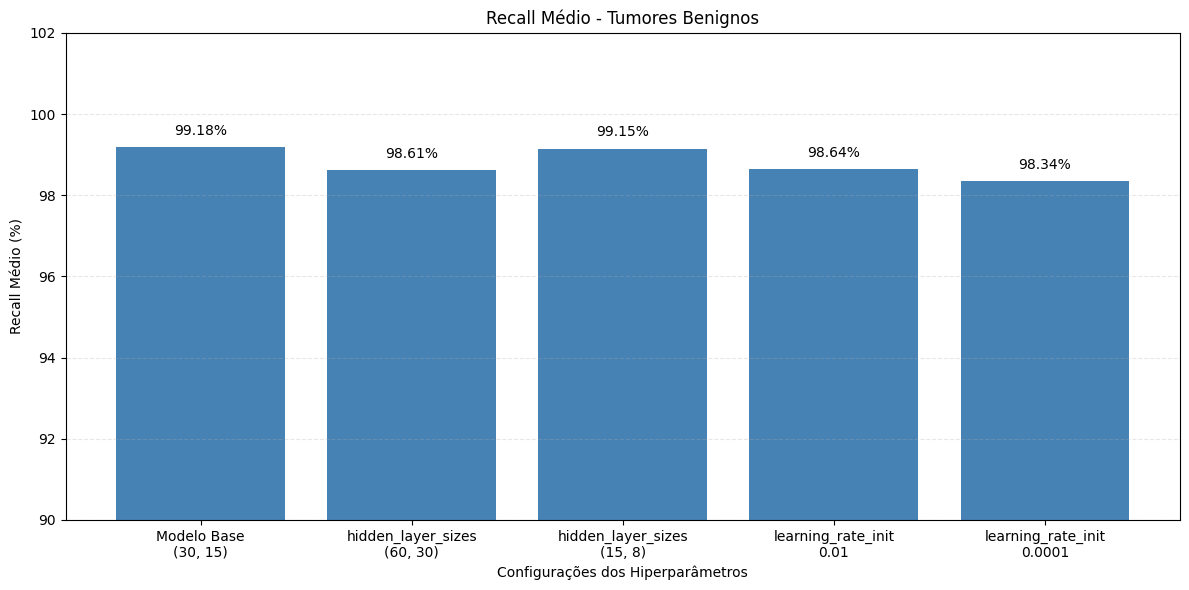

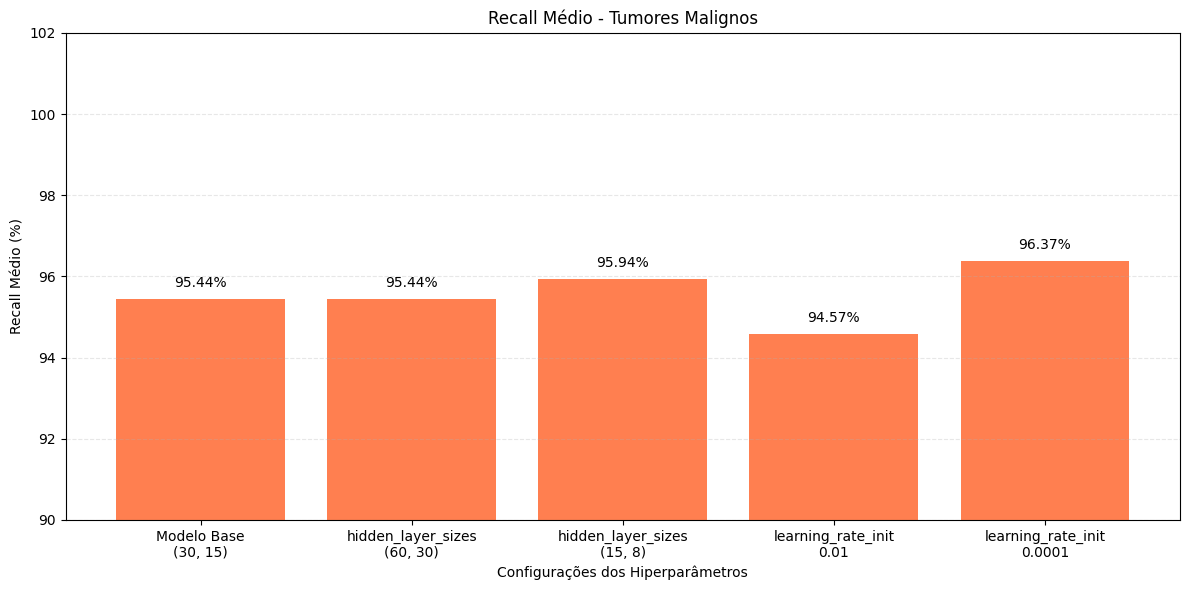

In [23]:

import matplotlib.pyplot as plt

modelos = [
    "Modelo Base\n(30, 15)",
    "hidden_layer_sizes\n(60, 30)",
    "hidden_layer_sizes\n(15, 8)",
    "learning_rate_init\n0.01",
    "learning_rate_init\n0.0001"
]

recall_benignos = [99.18, 98.61, 99.15, 98.64, 98.34]
recall_malignos = [95.44, 95.44, 95.94, 94.57, 96.37]

# GRÁFICO 1 - TUMORES BENIGNOS

plt.figure(figsize=(12, 6))

plt.bar(modelos, recall_benignos, color="steelblue")

plt.title("Recall Médio - Tumores Benignos")
plt.xlabel("Configurações dos Hiperparâmetros")
plt.ylabel("Recall Médio (%)")
plt.ylim(90, 102)

for i, valor in enumerate(recall_benignos):
    plt.text(i, valor + 0.3, f"{valor:.2f}%", ha="center")

plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()

plt.savefig("recall_benignos.png", dpi=300)
plt.show()


# GRÁFICO 2 - TUMORES MALIGNOS

plt.figure(figsize=(12, 6))

plt.bar(modelos, recall_malignos, color="coral")

plt.title("Recall Médio - Tumores Malignos")
plt.xlabel("Configurações dos Hiperparâmetros")
plt.ylabel("Recall Médio (%)")
plt.ylim(90, 102)

for i, valor in enumerate(recall_malignos):
    plt.text(i, valor + 0.3, f"{valor:.2f}%", ha="center")

plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()

plt.savefig("recall_malignos.png", dpi=300)
plt.show()


# Referência bibliográfica:

JOH NPHARMD. LaTeX.ipynb. Google Colaboratory, [s. d.]. Disponível em: https://colab.research.google.com/github/johnpharmd/DS-Sprint-03-Creating-Professional-Portfolios/blob/master/LaTeX.ipynb#scrollTo=ob-Stz7UBdKc. Acesso em: 9 nov. 2026.

SCIKIT-LEARN. MLPClassifier. Scikit-learn, [s. d.]. Disponível em: https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html. Acesso em: 9 nov. 2026.